<a href="https://colab.research.google.com/github/saheli56/Crime-Data/blob/main/CrimeData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CRIME DATA ANALYSIS - INDIA (Google Colab Version)

STEP 1: UPLOAD YOUR DATASET
------------------------------------------------------------
Please upload your 'crime_dataset_india.csv' file...



Saving crime_dataset_india.csv to crime_dataset_india.csv

✓ File 'crime_dataset_india.csv' uploaded successfully!


STEP 2: DATA PREPROCESSING
------------------------------------------------------------
Dataset loaded successfully!
Total Records: 40,160
Total Columns: 14

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40160 entries, 0 to 40159
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Report Number       40160 non-null  int64 
 1   Date Reported       40160 non-null  object
 2   Date of Occurrence  40160 non-null  object
 3   Time of Occurrence  40160 non-null  object
 4   City                40160 non-null  object
 5   Crime Code          40160 non-null  int64 
 6   Crime Description   40160 non-null  object
 7   Victim Age          40160 non-null  int64 
 8   Victim Gender       40160 non-null  object
 9   Weapon Used         34370 non-null  object
 10  Crime Domain        4

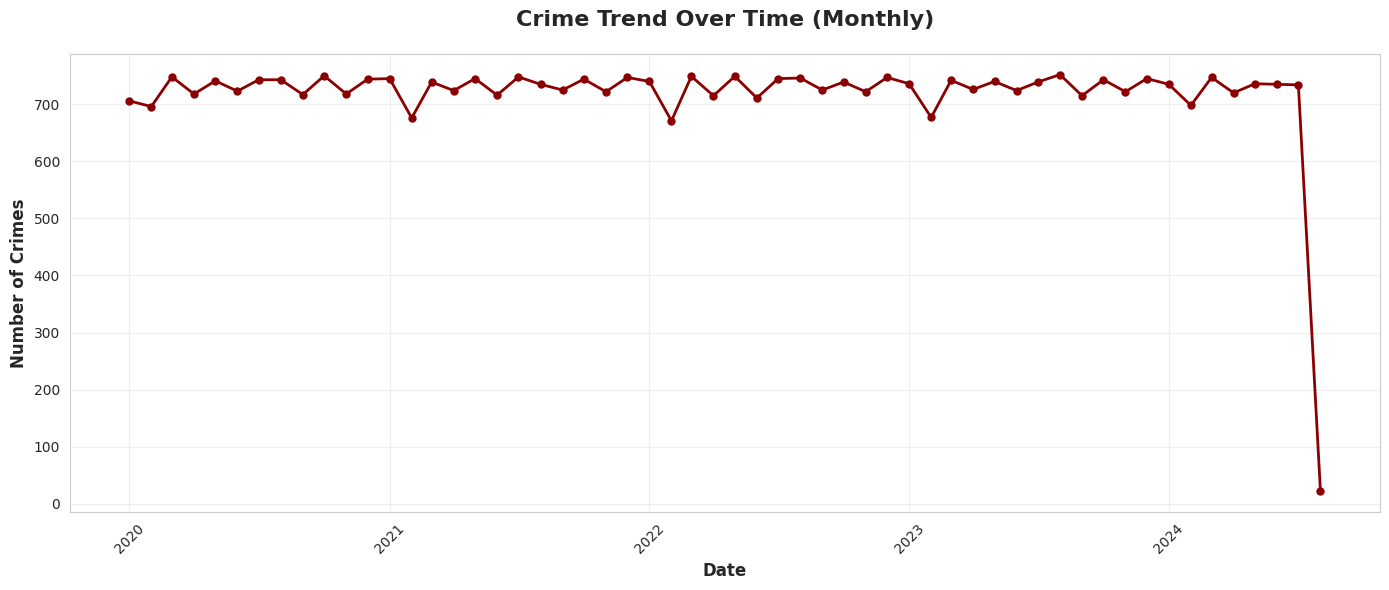


 INSIGHT:
   - Total crimes recorded: 40,160
   - Peak month: August 2023 (752 crimes)
   - Lowest month: August 2024 (22 crimes)
   - Average crimes per month: 717

 Visualization 2: Top Cities with Highest Crime
------------------------------------------------------------


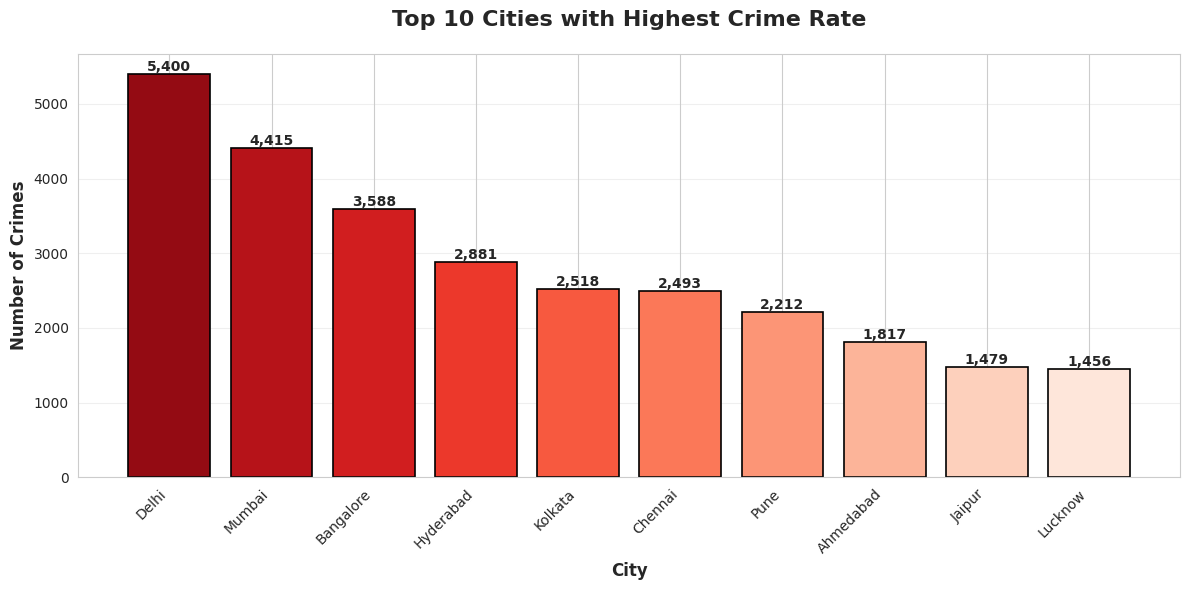


 INSIGHT:
   - Highest crime city: Delhi (5,400 crimes)
   - Second highest: Mumbai (4,415 crimes)
   - Third highest: Bangalore (3,588 crimes)
   - These top 10 cities account for 70.4% of all crimes

 Visualization 3: Crime Type Distribution
------------------------------------------------------------


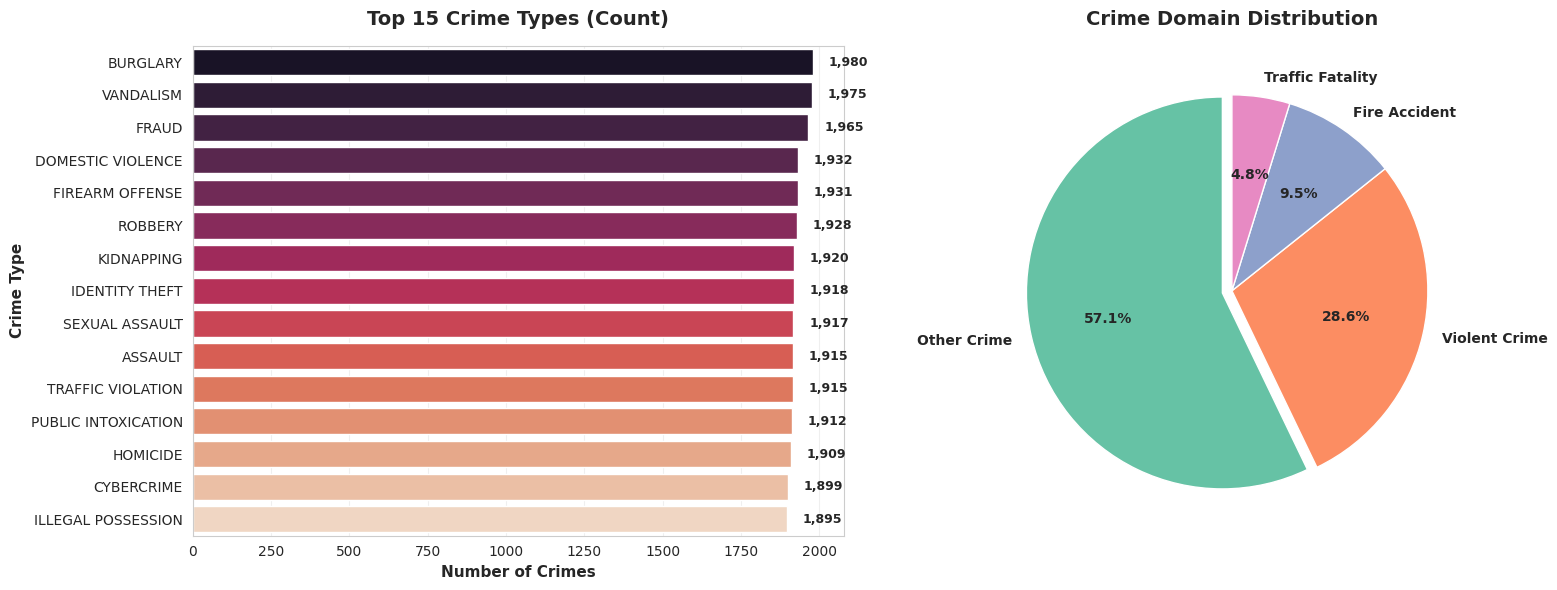


 INSIGHT:
   - Most common crime: BURGLARY (1,980 cases)
   - Most prevalent domain: Other Crime (22,948 cases, 57.1%)
   - Total unique crime types: 21

 Visualization 4: Crime by Victim Gender
------------------------------------------------------------


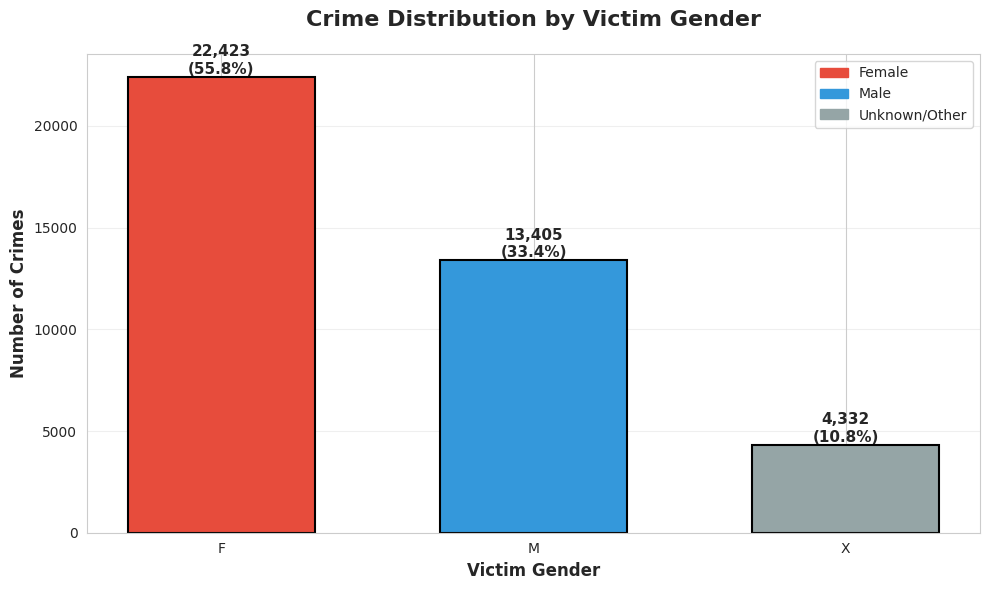


 INSIGHT:
   - Female victims: 22,423 (55.8%)
   - Male victims: 13,405 (33.4%)
   - Unknown/Other victims: 4,332 (10.8%)

 Visualization 5: Crime by Month (Seasonal Trends)
------------------------------------------------------------


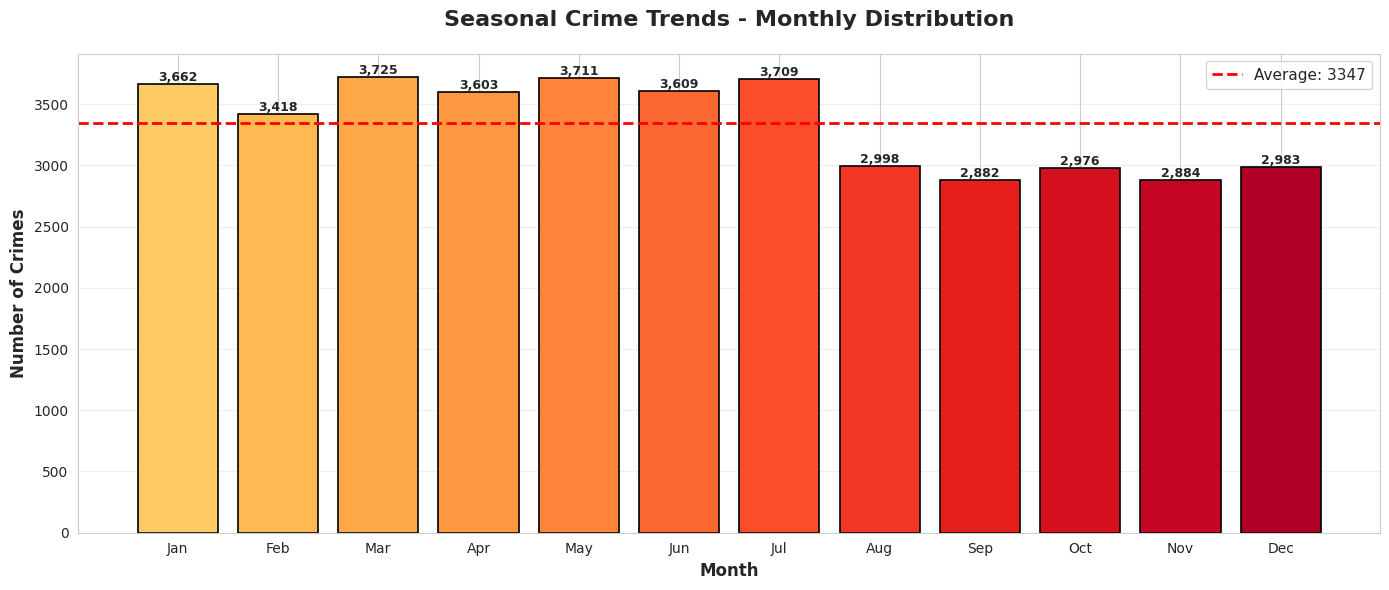


 INSIGHT:
   - Peak crime month: Mar (3,725 crimes)
   - Lowest crime month: Sep (2,882 crimes)
   - Average crimes per month: 3347

 Visualization 6: Correlation Heatmap
------------------------------------------------------------


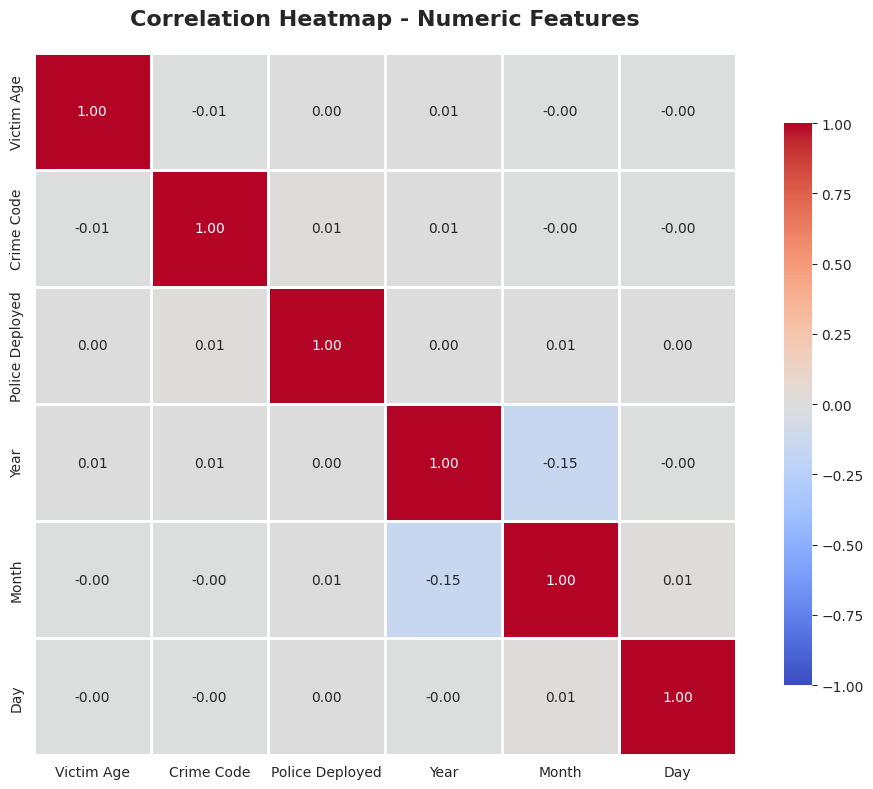


 INSIGHT:
   - Correlation analysis reveals relationships between numeric features
   - Values close to +1 indicate strong positive correlation
   - Values close to -1 indicate strong negative correlation


 Visualization 7: INDIA MAP - CRIME HOTSPOTS 



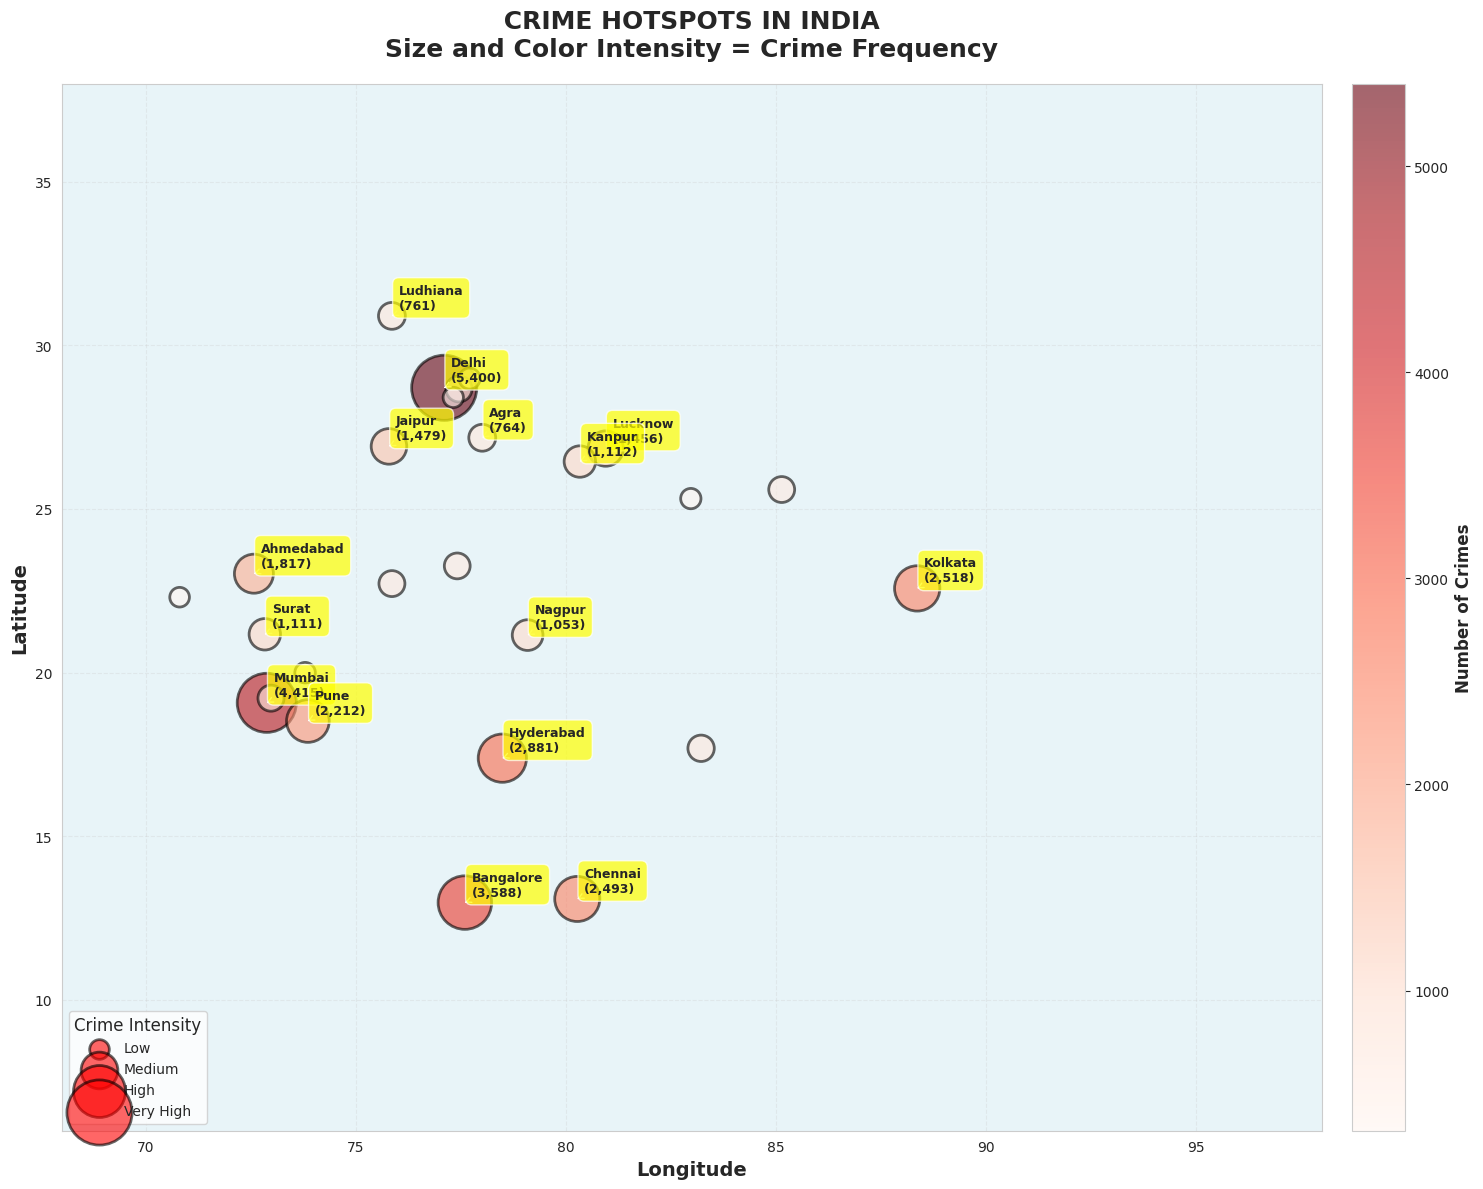


 INSIGHT - CRIME HOTSPOTS:
   - Total cities mapped: 26
   - Highest crime city: Delhi (5,400 crimes)
   - Second highest: Mumbai (4,415 crimes)
   - Third highest: Bangalore (3,588 crimes)


BONUS VISUALIZATIONS

Bonus Visualization 1: Weapon Usage Analysis
------------------------------------------------------------


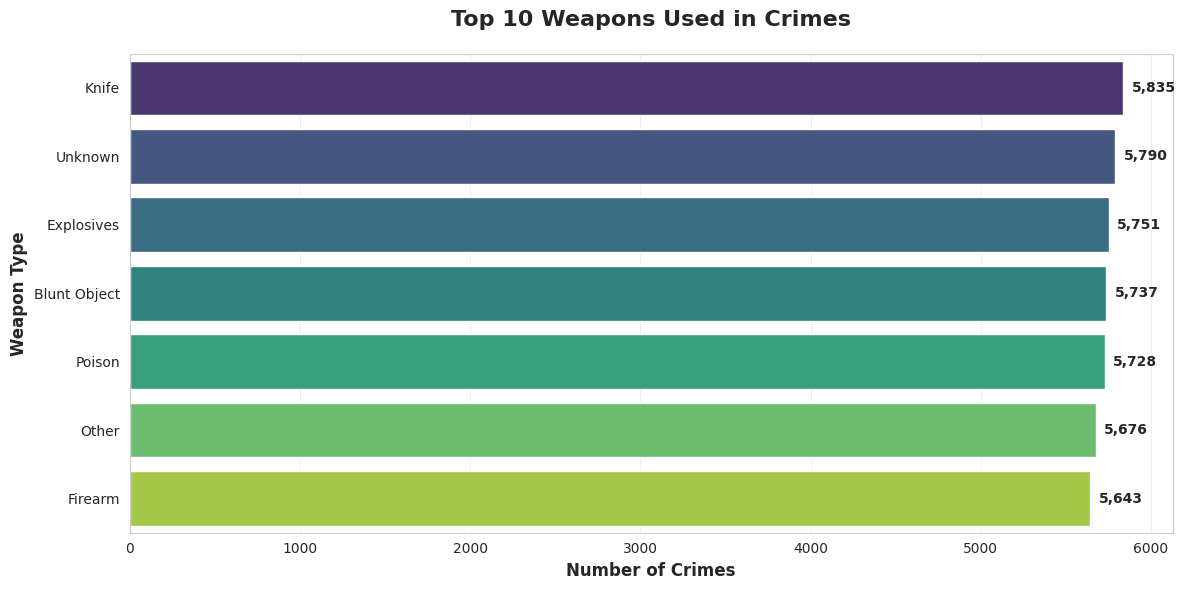


 INSIGHT:
   - Most used weapon: Knife (5,835 cases)

Bonus Visualization 2: Case Closure Rate
------------------------------------------------------------


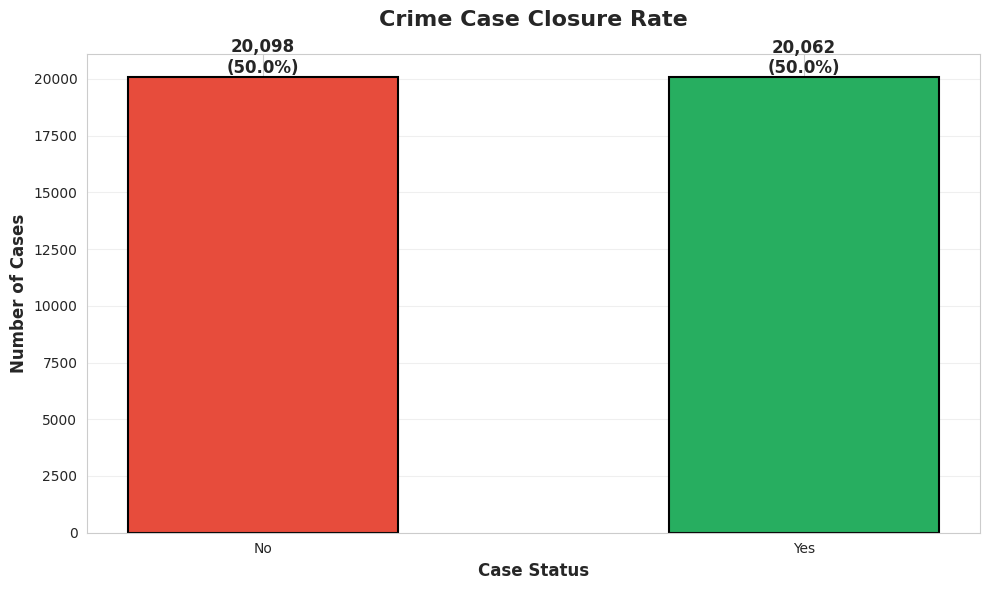


 INSIGHT:
   - Cases closed: 20,062 (50.0%)
   - Cases open: 20,098 (50.0%)
   - Closure rate assessment: Needs improvement


 ANALYSIS COMPLETE - SUMMARY STATISTICS

 KEY FINDINGS:
------------------------------------------------------------
1. Total Crimes Analyzed: 40,160
2. Date Range: January 2020 to August 2024
3. Total Cities: 29
4. Most Dangerous City: Delhi (5,400 crimes)
5. Most Common Crime: BURGLARY (1,980 cases)
6. Gender Distribution: 55.8% Female, 33.4% Male
7. Average Victim Age: 44.5 years
8. Case Closure Rate: 50.0%

 Thank you for using Crime Data Analysis System!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# For file upload in Colab
from google.colab import files
import io

# Set visualization style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("=" * 60)
print("CRIME DATA ANALYSIS - INDIA (Google Colab Version)")
print("=" * 60)
print()

print("STEP 1: UPLOAD YOUR DATASET")
print("-" * 60)
print("Please upload your 'crime_dataset_india.csv' file...")
print()

# Upload file
uploaded = files.upload()

# Get the filename
filename = list(uploaded.keys())[0]
print(f"\n✓ File '{filename}' uploaded successfully!")
print()

print("\nSTEP 2: DATA PREPROCESSING")
print("-" * 60)

# Load the dataset
df = pd.read_csv(io.BytesIO(uploaded[filename]), encoding='utf-8-sig')

print(f"Dataset loaded successfully!")
print(f"Total Records: {len(df):,}")
print(f"Total Columns: {len(df.columns)}")
print()

# Display basic information
print("Dataset Info:")
print(df.info())
print()

# Display first few rows
print("\nFirst 5 rows of data:")
print(df.head())
print()

# Check for missing values
print("\nMissing Values Summary:")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])
print()

# Convert 'Date Reported' to datetime format
df['Date Reported'] = pd.to_datetime(df['Date Reported'], format='%d-%m-%Y %H:%M', errors='coerce')

# Extract Year, Month, Day from Date Reported
df['Year'] = df['Date Reported'].dt.year
df['Month'] = df['Date Reported'].dt.month
df['Day'] = df['Date Reported'].dt.day
df['Month_Name'] = df['Date Reported'].dt.month_name()

print("✓ Date preprocessing completed!")
print(f"Date range: {df['Date Reported'].min()} to {df['Date Reported'].max()}")
print()

# Handle missing values
numeric_cols = df.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        df[col].fillna(df[col].median(), inplace=True)

categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col].fillna('Unknown', inplace=True)

print("✓ Missing values handled successfully!")
print()

# Display cleaned dataset statistics
print("Dataset Statistics:")
print(df.describe())
print()

print("\n" + "=" * 60)
print("STEP 3: EXPLORATORY DATA ANALYSIS (EDA)")
print("=" * 60)
print()

print(" Visualization 1: Crime Trend Over Time")
print("-" * 60)

plt.figure(figsize=(14, 6))
crime_trend = df.groupby(df['Date Reported'].dt.to_period('M')).size()
crime_trend.index = crime_trend.index.to_timestamp()

plt.plot(crime_trend.index, crime_trend.values, marker='o', linewidth=2,
         markersize=5, color='darkred')
plt.title('Crime Trend Over Time (Monthly)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Date', fontsize=12, fontweight='bold')
plt.ylabel('Number of Crimes', fontsize=12, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\n INSIGHT:")
print(f"   - Total crimes recorded: {len(df):,}")
print(f"   - Peak month: {crime_trend.idxmax().strftime('%B %Y')} ({crime_trend.max()} crimes)")
print(f"   - Lowest month: {crime_trend.idxmin().strftime('%B %Y')} ({crime_trend.min()} crimes)")
print(f"   - Average crimes per month: {crime_trend.mean():.0f}")
print()

print(" Visualization 2: Top Cities with Highest Crime")
print("-" * 60)

plt.figure(figsize=(12, 6))
top_cities = df['City'].value_counts().head(10)

colors = sns.color_palette('Reds_r', n_colors=10)
bars = plt.bar(range(len(top_cities)), top_cities.values, color=colors,
               edgecolor='black', linewidth=1.2)

# Add value labels on bars
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height):,}',
             ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.title('Top 10 Cities with Highest Crime Rate', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('City', fontsize=12, fontweight='bold')
plt.ylabel('Number of Crimes', fontsize=12, fontweight='bold')
plt.xticks(range(len(top_cities)), top_cities.index, rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("\n INSIGHT:")
print(f"   - Highest crime city: {top_cities.index[0]} ({top_cities.values[0]:,} crimes)")
print(f"   - Second highest: {top_cities.index[1]} ({top_cities.values[1]:,} crimes)")
print(f"   - Third highest: {top_cities.index[2]} ({top_cities.values[2]:,} crimes)")
print(f"   - These top 10 cities account for {(top_cities.sum()/len(df)*100):.1f}% of all crimes")
print()


print(" Visualization 3: Crime Type Distribution")
print("-" * 60)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Bar plot for crime types
top_crimes = df['Crime Description'].value_counts().head(15)
sns.barplot(x=top_crimes.values, y=top_crimes.index, palette='rocket', ax=ax1)
ax1.set_title('Top 15 Crime Types (Count)', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Number of Crimes', fontsize=11, fontweight='bold')
ax1.set_ylabel('Crime Type', fontsize=11, fontweight='bold')
ax1.grid(axis='x', alpha=0.3)

for i, v in enumerate(top_crimes.values):
    ax1.text(v + 50, i, f'{v:,}', va='center', fontweight='bold', fontsize=9)

# Pie chart for Crime Domain
domain_counts = df['Crime Domain'].value_counts()
colors_pie = sns.color_palette('Set2', n_colors=len(domain_counts))
explode = [0.05] + [0] * (len(domain_counts) - 1)

ax2.pie(domain_counts.values, labels=domain_counts.index, autopct='%1.1f%%',
        startangle=90, colors=colors_pie, explode=explode,
        textprops={'fontsize': 10, 'fontweight': 'bold'})
ax2.set_title('Crime Domain Distribution', fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

print("\n INSIGHT:")
print(f"   - Most common crime: {top_crimes.index[0]} ({top_crimes.values[0]:,} cases)")
print(f"   - Most prevalent domain: {domain_counts.index[0]} ({domain_counts.values[0]:,} cases, {domain_counts.values[0]/len(df)*100:.1f}%)")
print(f"   - Total unique crime types: {df['Crime Description'].nunique()}")
print()


print(" Visualization 4: Crime by Victim Gender")
print("-" * 60)

plt.figure(figsize=(10, 6))
gender_counts = df['Victim Gender'].value_counts()

colors_gender = {'M': '#3498db', 'F': '#e74c3c', 'X': '#95a5a6'}
color_list = [colors_gender.get(g, '#95a5a6') for g in gender_counts.index]

bars = plt.bar(gender_counts.index, gender_counts.values, color=color_list,
               edgecolor='black', linewidth=1.5, width=0.6)

# Add value labels
for i, bar in enumerate(bars):
    height = bar.get_height()
    percentage = (height / len(df)) * 100
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height):,}\n({percentage:.1f}%)',
             ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.title('Crime Distribution by Victim Gender', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Victim Gender', fontsize=12, fontweight='bold')
plt.ylabel('Number of Crimes', fontsize=12, fontweight='bold')
plt.grid(axis='y', alpha=0.3)

# Add legend
legend_labels = {'M': 'Male', 'F': 'Female', 'X': 'Unknown/Other'}
legend_handles = [plt.Rectangle((0,0),1,1, color=colors_gender[k]) for k in gender_counts.index]
legend_text = [legend_labels.get(k, k) for k in gender_counts.index]
plt.legend(legend_handles, legend_text, loc='upper right', fontsize=10)

plt.tight_layout()
plt.show()

print("\n INSIGHT:")
for gender in gender_counts.index:
    count = gender_counts[gender]
    pct = (count / len(df)) * 100
    gender_name = {'M': 'Male', 'F': 'Female', 'X': 'Unknown/Other'}.get(gender, gender)
    print(f"   - {gender_name} victims: {count:,} ({pct:.1f}%)")
print()


print(" Visualization 5: Crime by Month (Seasonal Trends)")
print("-" * 60)

plt.figure(figsize=(14, 6))
monthly_crimes = df.groupby('Month').size().reindex(range(1, 13), fill_value=0)
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Create gradient colors
colors_gradient = plt.cm.YlOrRd(np.linspace(0.3, 0.9, 12))

bars = plt.bar(range(1, 13), monthly_crimes.values, color=colors_gradient,
               edgecolor='black', linewidth=1.2)

# Add value labels
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height):,}',
             ha='center', va='bottom', fontweight='bold', fontsize=9)

plt.title('Seasonal Crime Trends - Monthly Distribution', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Month', fontsize=12, fontweight='bold')
plt.ylabel('Number of Crimes', fontsize=12, fontweight='bold')
plt.xticks(range(1, 13), month_names)
plt.grid(axis='y', alpha=0.3)

# Add average line
avg_crimes = monthly_crimes.mean()
plt.axhline(y=avg_crimes, color='red', linestyle='--', linewidth=2,
            label=f'Average: {avg_crimes:.0f}')
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

print("\n INSIGHT:")
peak_month = monthly_crimes.idxmax()
lowest_month = monthly_crimes.idxmin()
print(f"   - Peak crime month: {month_names[peak_month-1]} ({monthly_crimes[peak_month]:,} crimes)")
print(f"   - Lowest crime month: {month_names[lowest_month-1]} ({monthly_crimes[lowest_month]:,} crimes)")
print(f"   - Average crimes per month: {monthly_crimes.mean():.0f}")
print()

print(" Visualization 6: Correlation Heatmap")
print("-" * 60)

numeric_data = df[['Victim Age', 'Crime Code', 'Police Deployed', 'Year', 'Month', 'Day']]

plt.figure(figsize=(10, 8))
correlation_matrix = numeric_data.corr()

sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1)

plt.title('Correlation Heatmap - Numeric Features', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n INSIGHT:")
print("   - Correlation analysis reveals relationships between numeric features")
print("   - Values close to +1 indicate strong positive correlation")
print("   - Values close to -1 indicate strong negative correlation")
print()


print("\n" + "=" * 60)
print(" Visualization 7: INDIA MAP - CRIME HOTSPOTS ")
print("=" * 60)
print()

# Dictionary of major Indian cities with coordinates
indian_cities_coords = {
    'Mumbai': (19.0760, 72.8777),
    'Delhi': (28.7041, 77.1025),
    'Bangalore': (12.9716, 77.5946),
    'Hyderabad': (17.3850, 78.4867),
    'Ahmedabad': (23.0225, 72.5714),
    'Chennai': (13.0827, 80.2707),
    'Kolkata': (22.5726, 88.3639),
    'Pune': (18.5204, 73.8567),
    'Jaipur': (26.9124, 75.7873),
    'Surat': (21.1702, 72.8311),
    'Lucknow': (26.8467, 80.9462),
    'Kanpur': (26.4499, 80.3319),
    'Nagpur': (21.1458, 79.0882),
    'Indore': (22.7196, 75.8577),
    'Thane': (19.2183, 72.9781),
    'Bhopal': (23.2599, 77.4126),
    'Visakhapatnam': (17.6868, 83.2185),
    'Pimpri-Chinchwad': (18.6298, 73.7997),
    'Patna': (25.5941, 85.1376),
    'Vadodara': (22.3072, 73.1812),
    'Ghaziabad': (28.6692, 77.4538),
    'Ludhiana': (30.9010, 75.8573),
    'Agra': (27.1767, 78.0081),
    'Nashik': (19.9975, 73.7898),
    'Faridabad': (28.4089, 77.3178),
    'Meerut': (28.9845, 77.7064),
    'Rajkot': (22.3039, 70.8022),
    'Varanasi': (25.3176, 82.9739),
}

# Aggregate crime count per city
city_crime_count = df['City'].value_counts()

# Prepare data for mapping
cities_to_plot = []
crime_counts = []
latitudes = []
longitudes = []

for city, coords in indian_cities_coords.items():
    if city in city_crime_count.index:
        cities_to_plot.append(city)
        crime_counts.append(city_crime_count[city])
        latitudes.append(coords[0])
        longitudes.append(coords[1])

# Create the map
fig, ax = plt.subplots(figsize=(16, 12))

# Set India boundaries
ax.set_xlim(68, 98)
ax.set_ylim(6, 38)

# Normalize sizes
max_crimes = max(crime_counts)
min_crimes = min(crime_counts)
sizes = [(count - min_crimes) / (max_crimes - min_crimes) * 2000 + 200 for count in crime_counts]

# Plot scatter points
scatter = ax.scatter(longitudes, latitudes, s=sizes, c=crime_counts,
                    cmap='Reds', alpha=0.6, edgecolors='black', linewidth=2)

# Add labels for top 15 cities
top_cities_indices = sorted(range(len(crime_counts)), key=lambda i: crime_counts[i], reverse=True)[:15]
for idx in top_cities_indices:
    ax.annotate(f'{cities_to_plot[idx]}\n({crime_counts[idx]:,})',
                xy=(longitudes[idx], latitudes[idx]),
                xytext=(5, 5), textcoords='offset points',
                fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.7),
                arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0', lw=1))

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label('Number of Crimes', fontsize=12, fontweight='bold')

# Styling
ax.set_xlabel('Longitude', fontsize=14, fontweight='bold')
ax.set_ylabel('Latitude', fontsize=14, fontweight='bold')
ax.set_title(' CRIME HOTSPOTS IN INDIA \nSize and Color Intensity = Crime Frequency',
             fontsize=18, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_facecolor('#e8f4f8')

# Add legend
legend_sizes = [200, 700, 1400, 2200]
legend_labels = ['Low', 'Medium', 'High', 'Very High']
legend_handles = [plt.scatter([], [], s=s, c='red', alpha=0.6, edgecolors='black', linewidth=2)
                  for s in legend_sizes]
ax.legend(legend_handles, legend_labels, scatterpoints=1, loc='lower left',
          title='Crime Intensity', fontsize=10, title_fontsize=12)

plt.tight_layout()
plt.show()

print("\n INSIGHT - CRIME HOTSPOTS:")
print(f"   - Total cities mapped: {len(cities_to_plot)}")
print(f"   - Highest crime city: {cities_to_plot[top_cities_indices[0]]} ({crime_counts[top_cities_indices[0]]:,} crimes)")
print(f"   - Second highest: {cities_to_plot[top_cities_indices[1]]} ({crime_counts[top_cities_indices[1]]:,} crimes)")
print(f"   - Third highest: {cities_to_plot[top_cities_indices[2]]} ({crime_counts[top_cities_indices[2]]:,} crimes)")
print()


print("\n" + "=" * 60)
print("BONUS VISUALIZATIONS")
print("=" * 60)
print()


print("Bonus Visualization 1: Weapon Usage Analysis")
print("-" * 60)

plt.figure(figsize=(12, 6))
weapon_counts = df['Weapon Used'].value_counts().head(10)

sns.barplot(x=weapon_counts.values, y=weapon_counts.index, palette='viridis')
plt.title('Top 10 Weapons Used in Crimes', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Number of Crimes', fontsize=12, fontweight='bold')
plt.ylabel('Weapon Type', fontsize=12, fontweight='bold')
plt.grid(axis='x', alpha=0.3)

for i, v in enumerate(weapon_counts.values):
    plt.text(v + 50, i, f'{v:,}', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n INSIGHT:")
print(f"   - Most used weapon: {weapon_counts.index[0]} ({weapon_counts.values[0]:,} cases)")
print()


print("Bonus Visualization 2: Case Closure Rate")
print("-" * 60)

plt.figure(figsize=(10, 6))
closure_counts = df['Case Closed'].value_counts()

colors_closure = {'Yes': '#27ae60', 'No': '#e74c3c'}
color_list_closure = [colors_closure.get(status, '#95a5a6') for status in closure_counts.index]

bars = plt.bar(closure_counts.index, closure_counts.values, color=color_list_closure,
               edgecolor='black', linewidth=1.5, width=0.5)

for i, bar in enumerate(bars):
    height = bar.get_height()
    percentage = (height / len(df)) * 100
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height):,}\n({percentage:.1f}%)',
             ha='center', va='bottom', fontweight='bold', fontsize=12)

plt.title('Crime Case Closure Rate', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Case Status', fontsize=12, fontweight='bold')
plt.ylabel('Number of Cases', fontsize=12, fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("\n INSIGHT:")
if 'Yes' in closure_counts.index and 'No' in closure_counts.index:
    closure_rate = (closure_counts['Yes'] / len(df)) * 100
    print(f"   - Cases closed: {closure_counts['Yes']:,} ({closure_rate:.1f}%)")
    print(f"   - Cases open: {closure_counts['No']:,} ({100-closure_rate:.1f}%)")
    print(f"   - Closure rate assessment: {'Good' if closure_rate > 50 else 'Needs improvement'}")
print()


print("\n" + "=" * 60)
print(" ANALYSIS COMPLETE - SUMMARY STATISTICS")
print("=" * 60)
print()

print(" KEY FINDINGS:")
print("-" * 60)
print(f"1. Total Crimes Analyzed: {len(df):,}")
print(f"2. Date Range: {df['Date Reported'].min().strftime('%B %Y')} to {df['Date Reported'].max().strftime('%B %Y')}")
print(f"3. Total Cities: {df['City'].nunique()}")
print(f"4. Most Dangerous City: {df['City'].value_counts().index[0]} ({df['City'].value_counts().values[0]:,} crimes)")
print(f"5. Most Common Crime: {df['Crime Description'].value_counts().index[0]} ({df['Crime Description'].value_counts().values[0]:,} cases)")
print(f"6. Gender Distribution: {(df['Victim Gender'].value_counts().get('F', 0)/len(df)*100):.1f}% Female, {(df['Victim Gender'].value_counts().get('M', 0)/len(df)*100):.1f}% Male")
print(f"7. Average Victim Age: {df['Victim Age'].mean():.1f} years")
print(f"8. Case Closure Rate: {(df['Case Closed'].value_counts().get('Yes', 0)/len(df)*100):.1f}%")
print()

print("=" * 60)
print(" Thank you for using Crime Data Analysis System!")
print("=" * 60)
